<a href="https://colab.research.google.com/github/KausalyaBalasubramanian/RA-CGMA-Pneumonia-Detection/blob/main/RA_GCMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RA-GCMA: Reliability-Aware Gated Cross-Modal Attention for Pneumonia Diagnosis
Colab re-implementation using the **Open-I / Indiana University Chest X-ray collection** (free, no credentialing; paired frontal X-rays + radiology reports) in place of MIMIC-CXR.

**Runtime → Change runtime type → T4 GPU**, then run all cells top to bottom.

Pipeline: ResNet50 (image) + BioBERT (report) → cross-modal attention → reliability-aware gate → pneumonia / non-pneumonia.

In [ ]:
!pip -q install transformers scikit-learn
import os, re, glob, random, warnings, xml.etree.ElementTree as ET
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms as T
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)
warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev)
os.makedirs('/content/outputs', exist_ok=True)

# ---- Config (Table 1 of the paper) ----
CFG = dict(img_size=224, max_len=256, lr=1e-4, batch=16, epochs=30, d=256, heads=4)
# Open-I labels come from the report text, so the words that define the label would make
# the text branch trivially perfect. True = remove those words from the text the model sees.
MASK_LABEL_TERMS = True
pd.DataFrame({'Component':['Dataset','Image encoder','Text encoder','Cross-modal module','Fusion module','Output classes',
 'Input image size','Maximum text length','Optimizer','Initial learning rate','Batch size','Epochs','Evaluation metrics'],
 'Configuration':['Open-I (Indiana Univ.) Chest X-ray + reports','ResNet50 (ImageNet)','BioBERT (dmis-lab/biobert-base-cased-v1.1)',
 'Cross-modal attention','Reliability-aware gated fusion',2,'224 x 224',256,'AdamW',CFG['lr'],CFG['batch'],CFG['epochs'],
 'Accuracy, Precision, Recall, Specificity, F1, AUROC, AUPRC']})

device: cuda


,Component,Configuration
0,Dataset,Open-I (Indiana Univ.) Chest X-ray + reports
1,Image encoder,ResNet50 (ImageNet)
2,Text encoder,BioBERT (dmis-lab/biobert-base-cased-v1.1)
3,Cross-modal module,Cross-modal attention
4,Fusion module,Reliability-aware gated fusion
5,Output classes,2
6,Input image size,224 x 224
7,Maximum text length,256
8,Optimizer,AdamW
9,Initial learning rate,0.0001


## 1. Download the dataset (Open-I, NLM)

In [ ]:
os.makedirs('/content/openi/images', exist_ok=True); os.makedirs('/content/openi/reports', exist_ok=True)
base = 'https://openi.nlm.nih.gov/imgs/collections/'
!wget -nc -q -P /content/openi {base}NLMCXR_png.tgz
!wget -nc -q -P /content/openi {base}NLMCXR_reports.tgz
!tar -xzf /content/openi/NLMCXR_png.tgz -C /content/openi/images
!tar -xzf /content/openi/NLMCXR_reports.tgz -C /content/openi/reports
print(len(glob.glob('/content/openi/images/**/*.png', recursive=True)), 'images,',
      len(glob.glob('/content/openi/reports/**/*.xml', recursive=True)), 'reports')
# If the NLM link is down: download "Chest X-rays (Indiana University)" from Kaggle
# (raddar/chest-xrays-indiana-university), which holds the same data, and adapt the paths above.

7470 images, 3955 reports


## 2. Pair images with reports and create pneumonia labels

In [ ]:
png = {os.path.basename(p)[:-4]: p for p in glob.glob('/content/openi/images/**/*.png', recursive=True)}
POS = re.compile(r'pneumonia|pneumonitis|consolidation')
NEG = re.compile(r'\b(no|without|negative for|free of|resolved|absence of|ruled out|clear of)\b[^.]*?(pneumonia|pneumonitis|consolidation)')
def make_label(text, mesh):
    if any('pneumonia' in m for m in mesh): return 1
    return int(bool(POS.search(NEG.sub(' ', text.lower()))))

rows = []
for p in glob.glob('/content/openi/reports/**/*.xml', recursive=True):
    root = ET.parse(p).getroot()
    sec = {(a.get('Label') or '').upper(): (a.text or '') for a in root.iter('AbstractText')}
    text = (sec.get('FINDINGS','') + ' ' + sec.get('IMPRESSION','')).strip()
    mesh = [(m.text or '').lower() for m in root.iter('major')]
    ids = [i.get('id') for i in root.iter('parentImage') if i.get('id') in png]
    u = root.find('uId'); uid = u.get('id') if u is not None else os.path.basename(p)
    if len(text) < 10 or not ids: continue
    rows.append(dict(uid=uid, patient=re.sub(r'\D','',uid) or uid, img=png[ids[0]],
                     text=text, label=make_label(text, mesh)))
df = pd.DataFrame(rows).reset_index(drop=True)
df['text_model'] = df.text.str.replace(POS, '', regex=True) if MASK_LABEL_TERMS else df.text
print(len(df), 'paired image-report samples'); print(df.label.value_counts().rename({0:'non-pneumonia',1:'pneumonia'}))

# patient-level 80/10/10 split (no patient appears in two partitions)
sg = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = [f[1] for f in sg.split(df, df.label, df.patient)]
te_idx, va_idx = folds[0], folds[1]
tr_idx = np.setdiff1d(np.arange(len(df)), np.concatenate([te_idx, va_idx]))
print('train/val/test:', len(tr_idx), len(va_idx), len(te_idx), '| pneumonia in test:', int(df.label[te_idx].sum()))

3826 paired image-report samples
label
non-pneumonia    3703
pneumonia         123
Name: count, dtype: int64
train/val/test: 3060 383 383 | pneumonia in test: 16


## 3. Encoders: ResNet50 (visual tokens) and BioBERT (text tokens)
Encoders are run once and cached so all five models train in minutes.

In [ ]:
from transformers import BertTokenizer, BertTokenizerFast, BertModel

tf = T.Compose([T.Resize((CFG['img_size'],)*2), T.ToTensor(), T.Normalize([.485,.456,.406],[.229,.224,.225])])
class ImgDS(torch.utils.data.Dataset):
    def __init__(s, p): s.p = p
    def __len__(s): return len(s.p)
    def __getitem__(s, i): return tf(Image.open(s.p[i]).convert('RGB'))
rn = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
body = nn.Sequential(*list(rn.children())[:-2]).to(dev).eval()
feats = []
with torch.no_grad(), torch.autocast(dev, enabled=(dev=='cuda')):
    for x in torch.utils.data.DataLoader(ImgDS(df.img.tolist()), batch_size=64, num_workers=2):
        feats.append(body(x.to(dev)).flatten(2).transpose(1,2).half().cpu())
V = torch.cat(feats)                      # N x 49 x 2048
del body, rn

NAME = 'dmis-lab/biobert-base-cased-v1.1'
try:
    tok = BertTokenizer.from_pretrained(NAME, do_lower_case=False)
except Exception as e:
    print('Tokenizer fallback:', e)
    tok = BertTokenizerFast.from_pretrained('bert-base-cased', do_lower_case=False)

bert = BertModel.from_pretrained(NAME, add_pooling_layer=False).to(dev).eval()
tf_, ms = [], []
with torch.no_grad(), torch.autocast(dev, enabled=(dev=='cuda')):
    for i in range(0, len(df), 64):
        e = tok(df.text_model[i:i+64].tolist(), padding='max_length', truncation=True,
                max_length=CFG['max_len'], return_tensors='pt').to(dev)
        tf_.append(bert(**e).last_hidden_state.half().cpu()); ms.append(e['attention_mask'].cpu())
Tt, M = torch.cat(tf_), torch.cat(ms)     # N x 256 x 768, N x 256
del bert
Y = torch.tensor(df.label.values)
V, Tt, M, Y = V.to(dev), Tt.to(dev), M.to(dev), Y.to(dev)
print(V.shape, Tt.shape)

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arc

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

torch.Size([3826, 49, 2048]) torch.Size([3826, 256, 768])


In [ ]:
from transformers import BertTokenizerFast, BertTokenizer, BertModel

NAME = 'dmis-lab/biobert-base-cased-v1.1'
try:
    tok = BertTokenizer.from_pretrained(NAME, do_lower_case=False)
except Exception as e:
    print('Falling back to bert-base-cased vocab (BioBERT uses the same cased vocabulary):', e)
    tok = BertTokenizerFast.from_pretrained('bert-base-cased', do_lower_case=False)

# FIXED: Use BertModel instead of AutoModel to bypass the missing config 'model_type' key
bert = BertModel.from_pretrained(NAME, add_pooling_layer=False).to(dev).eval()
tf_, ms = [], []
with torch.no_grad(), torch.autocast(dev, enabled=(dev=='cuda')):
    for i in range(0, len(df), 64):
        e = tok(df.text_model[i:i+64].tolist(), padding='max_length', truncation=True,
                max_length=CFG['max_len'], return_tensors='pt').to(dev)
        tf_.append(bert(**e).last_hidden_state.half().cpu()); ms.append(e['attention_mask'].cpu())
Tt, M = torch.cat(tf_), torch.cat(ms)     # N x 256 x 768, N x 256
del bert
Y = torch.tensor(df.label.values)
V, Tt, M, Y = V.to(dev), Tt.to(dev), M.to(dev), Y.to(dev)
print(V.shape, Tt.shape)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arc

torch.Size([3826, 49, 2048]) torch.Size([3826, 256, 768])


In [ ]:
from transformers import BertModel, BertConfig, BertTokenizer, BertTokenizerFast

NAME = 'dmis-lab/biobert-base-cased-v1.1'
try:
    tok = BertTokenizer.from_pretrained(NAME, do_lower_case=False)
except Exception as e:
    print('Tokenizer fallback:', e)
    tok = BertTokenizerFast.from_pretrained('bert-base-cased', do_lower_case=False)

bert = BertModel.from_pretrained(NAME, add_pooling_layer=False).to(dev).eval()

tf_, ms = [], []
with torch.no_grad(), torch.autocast(dev, enabled=(dev=='cuda')):
    for i in range(0, len(df), 64):
        e = tok(df.text_model[i:i+64].tolist(), padding='max_length', truncation=True,
                max_length=CFG['max_len'], return_tensors='pt').to(dev)
        tf_.append(bert(**e).last_hidden_state.half().cpu()); ms.append(e['attention_mask'].cpu())
Tt, M = torch.cat(tf_), torch.cat(ms)     # N x 256 x 768, N x 256
del bert
Y = torch.tensor(df.label.values)
V, Tt, M, Y = V.to(dev), Tt.to(dev), M.to(dev), Y.to(dev)
print(V.shape, Tt.shape)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arc

torch.Size([3826, 49, 2048]) torch.Size([3826, 256, 768])


In [ ]:
png = {os.path.basename(p)[:-4]: p for p in glob.glob('/content/openi/images/**/*.png', recursive=True)}
POS = re.compile(r'pneumonia|pneumonitis|consolidation')
POS_I = re.compile(POS.pattern, re.I)          # case-insensitive version used for masking
NEG = re.compile(r'\b(no|without|negative for|free of|resolved|absence of|ruled out|clear of)\b[^.]*?(pneumonia|pneumonitis|consolidation)')
def make_label(text, mesh):
    if any('pneumonia' in m for m in mesh): return 1
    return int(bool(POS.search(NEG.sub(' ', text.lower()))))

rows = []
for p in glob.glob('/content/openi/reports/**/*.xml', recursive=True):
    root = ET.parse(p).getroot()
    sec = {(a.get('Label') or '').upper(): (a.text or '') for a in root.iter('AbstractText')}
    text = (sec.get('FINDINGS','') + ' ' + sec.get('IMPRESSION','')).strip()
    mesh = [(m.text or '').lower() for m in root.iter('major')]
    ids = [i.get('id') for i in root.iter('parentImage') if i.get('id') in png]
    u = root.find('uId'); uid = u.get('id') if u is not None else os.path.basename(p)
    if len(text) < 10 or not ids: continue
    rows.append(dict(uid=uid, patient=re.sub(r'\D','',uid) or uid, img=png[ids[0]],
                     text=text, label=make_label(text, mesh)))
df = pd.DataFrame(rows).reset_index(drop=True)

# FIXED: case-insensitive masking so "Pneumonia"/"Consolidation" can't leak the label into the text branch
df['text_model'] = df.text.str.replace(POS_I, '', regex=True) if MASK_LABEL_TERMS else df.text   # FIXED

print(len(df), 'paired image-report samples'); print(df.label.value_counts().rename({0:'non-pneumonia',1:'pneumonia'}))

# patient-level 80/10/10 split (no patient appears in two partitions)
sg = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = [f[1] for f in sg.split(df, df.label, df.patient)]
te_idx, va_idx = folds[0], folds[1]
tr_idx = np.setdiff1d(np.arange(len(df)), np.concatenate([te_idx, va_idx]))
print('train/val/test:', len(tr_idx), len(va_idx), len(te_idx), '| pneumonia in test:', int(df.label[te_idx].sum()))

3826 paired image-report samples
label
non-pneumonia    3703
pneumonia         123
Name: count, dtype: int64
train/val/test: 3060 383 383 | pneumonia in test: 16


## 4. Models: image-only, text-only, simple fusion, cross-modal attention, gated-only (ablation), RA-GCMA

In [ ]:
class Net(nn.Module):
    def __init__(s, mode, d=CFG['d'], h=CFG['heads']):
        super().__init__(); s.mode = mode
        blk = lambda i: nn.Sequential(nn.Linear(i,d), nn.LayerNorm(d), nn.GELU(), nn.Dropout(.2))
        s.pv, s.pt = blk(2048), blk(768)
        s.v2t = nn.MultiheadAttention(d, h, batch_first=True)   # image queries attend to report tokens
        s.t2v = nn.MultiheadAttention(d, h, batch_first=True)   # report queries attend to image tokens
        rel = lambda: nn.Sequential(nn.Linear(d,d//2), nn.GELU(), nn.Linear(d//2,1))
        s.rel_v, s.rel_t = rel(), rel()                          # reliability estimators
        s.cls = nn.Sequential(nn.Dropout(.3), nn.Linear(2*d if mode in ('simple','cross') else d, 128), nn.GELU(), nn.Linear(128,2))
    def forward(s, v, t, m):
        v, t = s.pv(v), s.pt(t); mf = m.unsqueeze(-1).float()
        mean_t = lambda x: (x*mf).sum(1) / mf.sum(1).clamp(min=1)
        gate = None
        if s.mode == 'image': z = v.mean(1)
        elif s.mode == 'text': z = mean_t(t)
        elif s.mode == 'simple': z = torch.cat([v.mean(1), mean_t(t)], -1)
        else:
            if s.mode in ('cross','ragcma'):
                v2,_ = s.v2t(v, t, t, key_padding_mask=(m==0)); t2,_ = s.t2v(t, v, v)
                hv, ht = (v+v2).mean(1), mean_t(t+t2)
            else:                                              # 'gated' = gating without cross-modal attention
                hv, ht = v.mean(1), mean_t(t)
            if s.mode == 'cross': z = torch.cat([hv, ht], -1)
            else:
                gate = torch.softmax(torch.cat([s.rel_v(hv), s.rel_t(ht)], -1), -1)   # [w_image, w_text]
                z = gate[:,:1]*hv + gate[:,1:]*ht
        return s.cls(z), gate

def metrics(y, p, thr=.5):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
    return dict(Accuracy=accuracy_score(y,yh)*100, Precision=precision_score(y,yh,zero_division=0)*100,
                Recall=recall_score(y,yh,zero_division=0)*100, Specificity=tn/max(tn+fp,1)*100,
                F1=f1_score(y,yh,zero_division=0)*100, AUROC=roc_auc_score(y,p)*100, AUPRC=average_precision_score(y,p)*100)

@torch.no_grad()
def predict(net, v, t, m):
    net.eval(); P, G = [], []
    for i in range(0, len(v), 256):
        lg, g = net(v[i:i+256].float(), t[i:i+256].float(), m[i:i+256])
        P.append(torch.softmax(lg,-1)[:,1].cpu()); G.append(g.cpu() if g is not None else torch.full((len(lg),2), float('nan')))
    return torch.cat(P).numpy(), torch.cat(G).numpy()

def train(mode):
    torch.manual_seed(SEED); net = Net(mode).to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=CFG['lr'], weight_decay=1e-2)
    tr = torch.tensor(tr_idx, device=dev); ytr = Y[tr]
    w = torch.tensor([1., float(((ytr==0).sum()/(ytr==1).sum().clamp(min=1)).sqrt())], device=dev)
    best, state = -1, None
    for ep in range(CFG['epochs']):
        net.train(); perm = tr[torch.randperm(len(tr), device=dev)]
        for i in range(0, len(perm), CFG['batch']):
            b = perm[i:i+CFG['batch']]
            lg,_ = net(V[b].float(), Tt[b].float(), M[b])
            loss = F.cross_entropy(lg, Y[b], weight=w); opt.zero_grad(); loss.backward(); opt.step()
        p,_ = predict(net, V[va_idx], Tt[va_idx], M[va_idx])
        sc = average_precision_score(df.label.values[va_idx], p)      # model selection on validation AUPRC
        if sc > best: best, state = sc, {k:v.clone() for k,v in net.state_dict().items()}
    net.load_state_dict(state); return net

names = {'image':'ResNet50 image-only','text':'BioBERT text-only','simple':'Simple feature fusion',
         'cross':'Cross-modal attention','gated':'Gated fusion (no cross-modal) [ablation]','ragcma':'RA-GCMA'}
nets, res = {}, {}
yte = df.label.values[te_idx]
for mode in names:
    nets[mode] = train(mode)
    p,_ = predict(nets[mode], V[te_idx], Tt[te_idx], M[te_idx]); res[names[mode]] = metrics(yte, p)
    print(f'{names[mode]:45s} acc={res[names[mode]]["Accuracy"]:.2f}  AUROC={res[names[mode]]["AUROC"]:.2f}')

ResNet50 image-only                           acc=95.30  AUROC=59.15
BioBERT text-only                             acc=96.34  AUROC=94.69
Simple feature fusion                         acc=96.08  AUROC=93.51
Cross-modal attention                         acc=96.34  AUROC=94.84
Gated fusion (no cross-modal) [ablation]      acc=95.82  AUROC=94.31
RA-GCMA                                       acc=96.08  AUROC=93.44


## 5. Table 2 – Multimodal performance & ablation

In [ ]:
t2 = pd.DataFrame(res).T.round(2); t2.index.name = 'Model'
display(t2[['Accuracy','Precision','Recall','F1','AUROC']].rename(columns={'Accuracy':'Accuracy (%)','Precision':'Precision (%)','Recall':'Recall (%)','F1':'F1-score (%)','AUROC':'AUROC (%)'}))
t2.to_csv('/content/outputs/table2_performance.csv')

,Accuracy (%),Precision (%),Recall (%),F1-score (%),AUROC (%)
Model,,,,,
ResNet50 image-only,95.30,25.00,6.25,10.00,59.15
BioBERT text-only,96.34,56.25,56.25,56.25,94.69
Simple feature fusion,96.08,66.67,12.50,21.05,93.51
Cross-modal attention,96.34,75.00,18.75,30.00,94.84
Gated fusion (no cross-modal) [ablation],95.82,50.00,62.50,55.56,94.31
RA-GCMA,96.08,54.55,37.50,44.44,93.44


## 6. Figure 2 – Accuracy progression

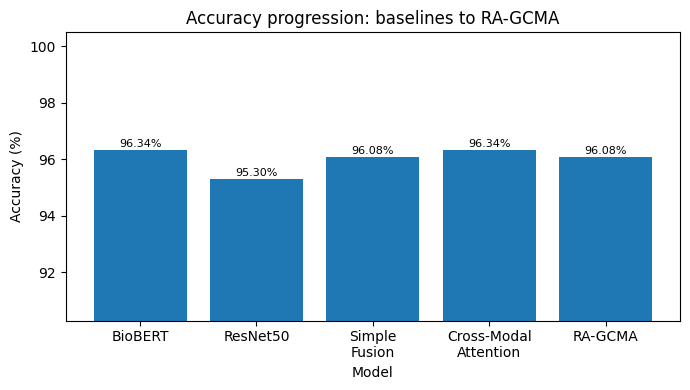

In [ ]:
order = ['BioBERT text-only','ResNet50 image-only','Simple feature fusion','Cross-modal attention','RA-GCMA']
acc = [res[k]['Accuracy'] for k in order]
plt.figure(figsize=(7,4)); b = plt.bar(['BioBERT','ResNet50','Simple\nFusion','Cross-Modal\nAttention','RA-GCMA'], acc, color='#1f77b4')
for r_, a in zip(b, acc): plt.text(r_.get_x()+r_.get_width()/2, a+.1, f'{a:.2f}%', ha='center', fontsize=8)
plt.ylabel('Accuracy (%)'); plt.xlabel('Model'); plt.ylim(max(0,min(acc)-5), 100.5)
plt.title('Accuracy progression: baselines to RA-GCMA'); plt.tight_layout(); plt.savefig('/content/outputs/fig2_accuracy.png', dpi=200); plt.show()

## 7. Figure 3 – Diagnostic performance profile of RA-GCMA

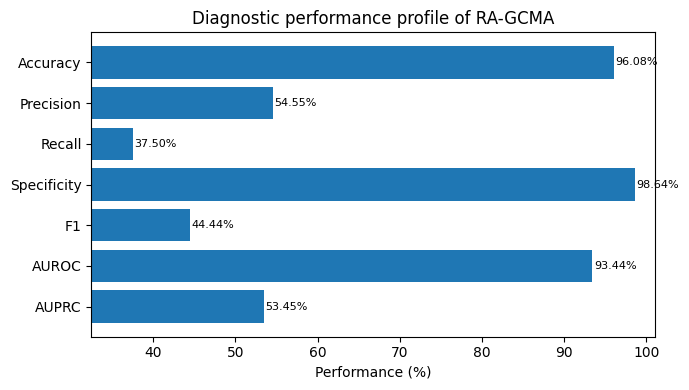

In [ ]:
m = res['RA-GCMA']; ks = ['Accuracy','Precision','Recall','Specificity','F1','AUROC','AUPRC']
plt.figure(figsize=(7,4)); b = plt.barh(ks[::-1], [m[k] for k in ks[::-1]], color='#1f77b4')
for r_, k in zip(b, ks[::-1]): plt.text(m[k]+.2, r_.get_y()+r_.get_height()/2, f'{m[k]:.2f}%', va='center', fontsize=8)
plt.xlabel('Performance (%)'); plt.xlim(max(0, min(m.values())-5), 101)
plt.title('Diagnostic performance profile of RA-GCMA'); plt.tight_layout(); plt.savefig('/content/outputs/fig3_profile.png', dpi=200); plt.show()

## 8. Table 3 – Comparison with previous studies
Literature numbers are copied from the paper; they come from different datasets and protocols, so they are **context, not a like-for-like comparison**.

In [ ]:
t3 = pd.DataFrame([
 ['[6]','Deep learning-based pneumonia detection',94.60],['[8]','Deep learning with Grad-CAM explainability',95.20],
 ['[12]','VGG16-enhanced CNN',96.10],['[17]','Modified DenseNet121',97.30],['[20]','Swin Transformer',97.80],
 ['Proposed RA-GCMA (this run, Open-I)','ResNet50 + BioBERT + gated cross-modal attention', round(res['RA-GCMA']['Accuracy'],2)]],
 columns=['Reference','Method / Approach','Reported Accuracy (%)'])
display(t3); t3.to_csv('/content/outputs/table3_comparison.csv', index=False)

,Reference,Method / Approach,Reported Accuracy (%)
0,[6],Deep learning-based pneumonia detection,94.60
1,[8],Deep learning with Grad-CAM explainability,95.20
2,[12],VGG16-enhanced CNN,96.10
3,[17],Modified DenseNet121,97.30
4,[20],Swin Transformer,97.80
5,"Proposed RA-GCMA (this run, Open-I)",ResNet50 + BioBERT + gated cross-modal attention,96.08


## 9. Modality-degradation experiment
Reports (or images) of test samples are swapped with those of other patients, i.e. made uninformative. A reliability-aware model should lean on the intact modality.

In [ ]:
def degraded(net, which):
    g = torch.Generator().manual_seed(0); perm = torch.randperm(len(te_idx), generator=g).to(dev)
    ti = torch.tensor(te_idx, device=dev); v, t, mk = V[ti], Tt[ti], M[ti]
    if which == 'text':  t, mk = t[perm], mk[perm]
    if which == 'image': v = v[perm]
    return predict(net, v, t, mk)
rows = []
for which in ['none','text','image']:
    for mode in ['simple','cross','ragcma']:
        p, g = degraded(nets[mode], which)
        rows.append(dict(Degraded=which, Model=names[mode], Accuracy=round(accuracy_score(yte,(p>=.5))*100,2),
                         AUROC=round(roc_auc_score(yte,p)*100,2),
                         Gate_image=round(float(np.nanmean(g[:,0])),3) if mode=='ragcma' else None,
                         Gate_text=round(float(np.nanmean(g[:,1])),3) if mode=='ragcma' else None))
deg = pd.DataFrame(rows); display(deg); deg.to_csv('/content/outputs/modality_degradation.csv', index=False)

,Degraded,Model,Accuracy,AUROC,Gate_image,Gate_text
0,none,Simple feature fusion,96.08,93.51,NaN,NaN
1,none,Cross-modal attention,96.34,94.84,NaN,NaN
2,none,RA-GCMA,96.08,93.44,0.036,0.964
3,text,Simple feature fusion,94.78,52.50,NaN,NaN
4,text,Cross-modal attention,94.52,43.63,NaN,NaN
5,text,RA-GCMA,92.95,58.67,0.037,0.963
6,image,Simple feature fusion,96.34,93.39,NaN,NaN
7,image,Cross-modal attention,96.87,96.19,NaN,NaN
8,image,RA-GCMA,97.13,94.65,0.035,0.965


## 10. Figure 4 – Prediction output with reliability weights and Grad-CAM
Change `k` to view another test sample.

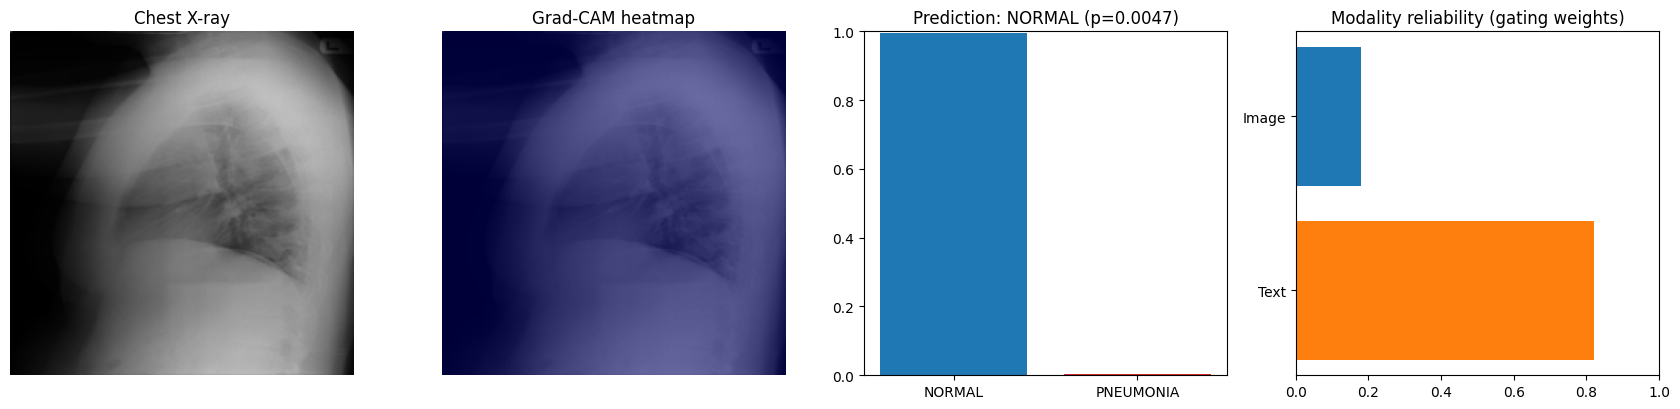

Ground truth: PNEUMONIA
Report: The heart is normal in size. There is right paratracheal density concerning for lymphadenopathy. There are patchy right upper lobe streaky opacities. The remainder of the lungs are clear. There is no pleural effusion. Patchy opacities in right upper lobe, concerning for pneumonia, given history. Right paratracheal density possibly reactive lymphadenopathy. Followup evaluation to resolution is recommended.


In [ ]:
import matplotlib.cm as cm
def show_prediction(k=0, save=None):
    i = int(te_idx[k]); net = nets['ragcma'].eval()
    v = V[i:i+1].float().clone().requires_grad_(True)
    lg, gate = net(v, Tt[i:i+1].float(), M[i:i+1]); prob = torch.softmax(lg,-1)[0].detach().cpu().numpy()
    net.zero_grad(); lg[0,1].backward()
    wch = v.grad.mean(1)                                          # channel weights (Grad-CAM)
    cam = F.relu((v.detach()*wch.unsqueeze(1)).sum(-1)).reshape(1,1,7,7)
    cam = F.interpolate(cam, size=(224,224), mode='bilinear')[0,0].cpu().numpy(); cam = (cam-cam.min())/(cam.max()-cam.min()+1e-8)
    img = Image.open(df.img[i]).convert('RGB').resize((224,224))
    fig, ax = plt.subplots(1, 4, figsize=(17,4.2))
    ax[0].imshow(img, cmap='gray'); ax[0].set_title('Chest X-ray'); ax[0].axis('off')
    ax[1].imshow(img); ax[1].imshow(cam, cmap='jet', alpha=.45); ax[1].set_title('Grad-CAM heatmap'); ax[1].axis('off')
    ax[2].bar(['NORMAL','PNEUMONIA'], prob, color=['#1f77b4','#d62728']); ax[2].set_ylim(0,1); ax[2].set_title(f'Prediction: {"PNEUMONIA" if prob[1]>=.5 else "NORMAL"} (p={prob[1]:.4f})')
    gt = gate[0].detach().cpu().numpy(); ax[3].barh(['Text','Image'], [gt[1], gt[0]], color=['#ff7f0e','#1f77b4']); ax[3].set_xlim(0,1); ax[3].set_title('Modality reliability (gating weights)')
    plt.tight_layout()
    if save: plt.savefig(save, dpi=200)
    plt.show(); print('Ground truth:', 'PNEUMONIA' if df.label[i] else 'NORMAL'); print('Report:', df.text[i][:600])
pos = [j for j,i in enumerate(te_idx) if df.label[i]==1]
show_prediction(pos[0] if pos else 0, '/content/outputs/fig4_prediction.png')

## 10b. Pneumonia / NORMAL identification (replaces the Gradio app)
Runs directly in Colab: classifies held-out test cases, or your own X-ray via `IMAGE_PATH` / `REPORT_TEXT`, and shows the predicted class, probabilities, Grad-CAM and modality reliability weights.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arc

validation-selected thresholds: {'ragcma': 0.24999999999999994, 'image': 0.06}


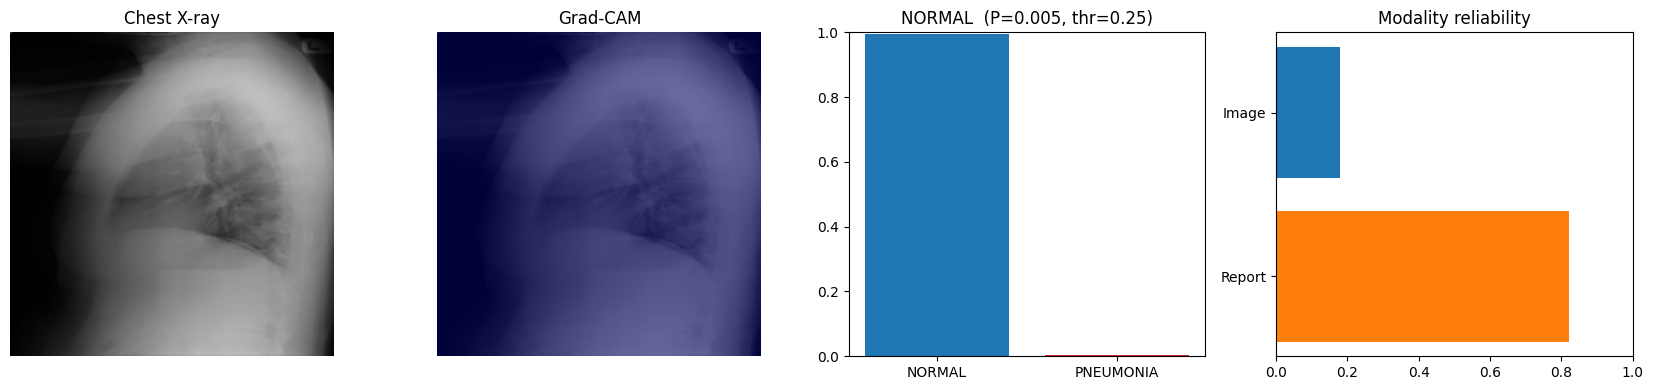

Prediction: NORMAL | P(PNEUMONIA)=0.0047  P(NORMAL)=0.9953 | threshold 0.25 | model: RA-GCMA (image + report) | reliability: image 0.179, report 0.821 | reference label: PNEUMONIA
----------------------------------------------------------------------------------------------------


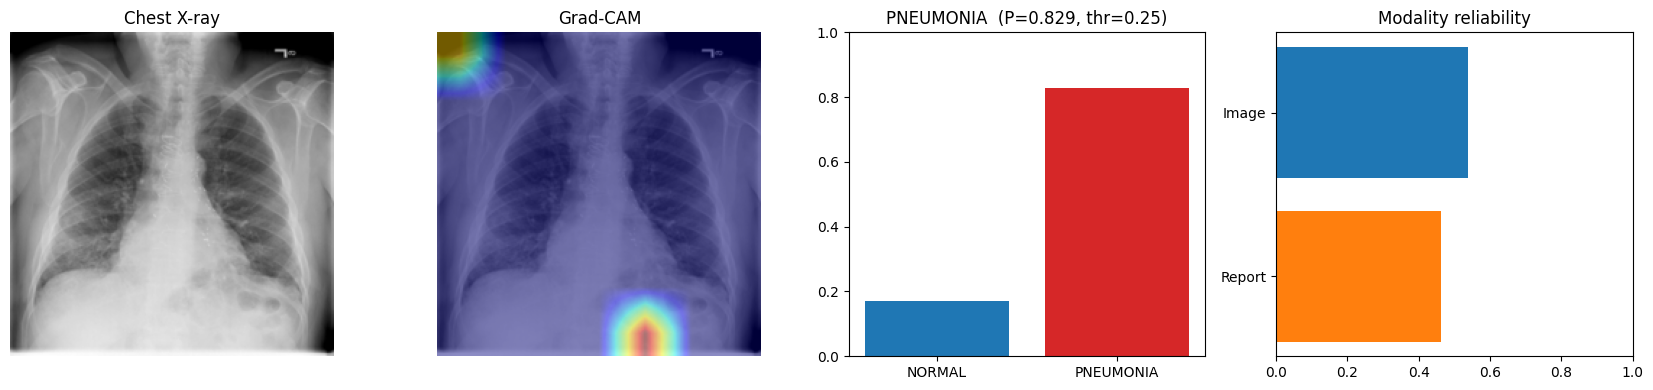

Prediction: PNEUMONIA | P(PNEUMONIA)=0.8291  P(NORMAL)=0.1709 | threshold 0.25 | model: RA-GCMA (image + report) | reliability: image 0.537, report 0.463 | reference label: PNEUMONIA
----------------------------------------------------------------------------------------------------


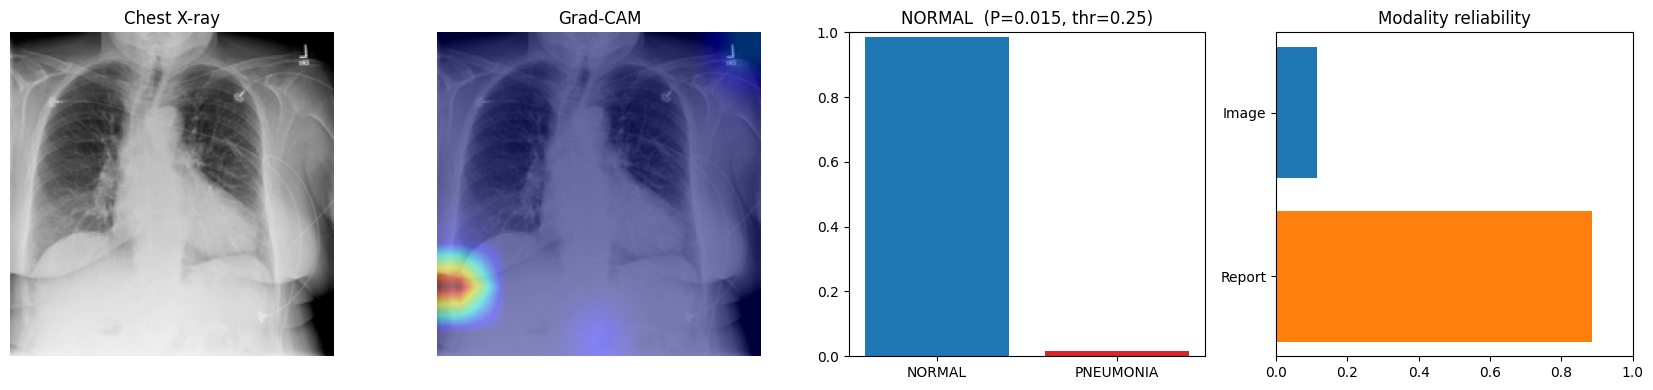

Prediction: NORMAL | P(PNEUMONIA)=0.0153  P(NORMAL)=0.9847 | threshold 0.25 | model: RA-GCMA (image + report) | reliability: image 0.115, report 0.885 | reference label: PNEUMONIA
----------------------------------------------------------------------------------------------------


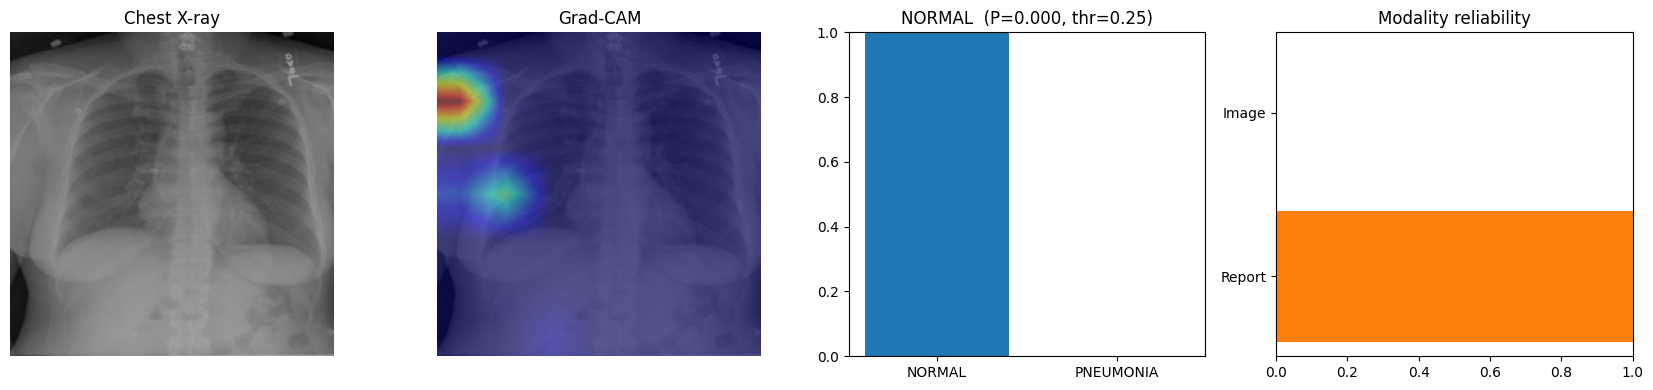

Prediction: NORMAL | P(PNEUMONIA)=0.0001  P(NORMAL)=0.9999 | threshold 0.25 | model: RA-GCMA (image + report) | reliability: image 0.000, report 1.000 | reference label: NORMAL
----------------------------------------------------------------------------------------------------


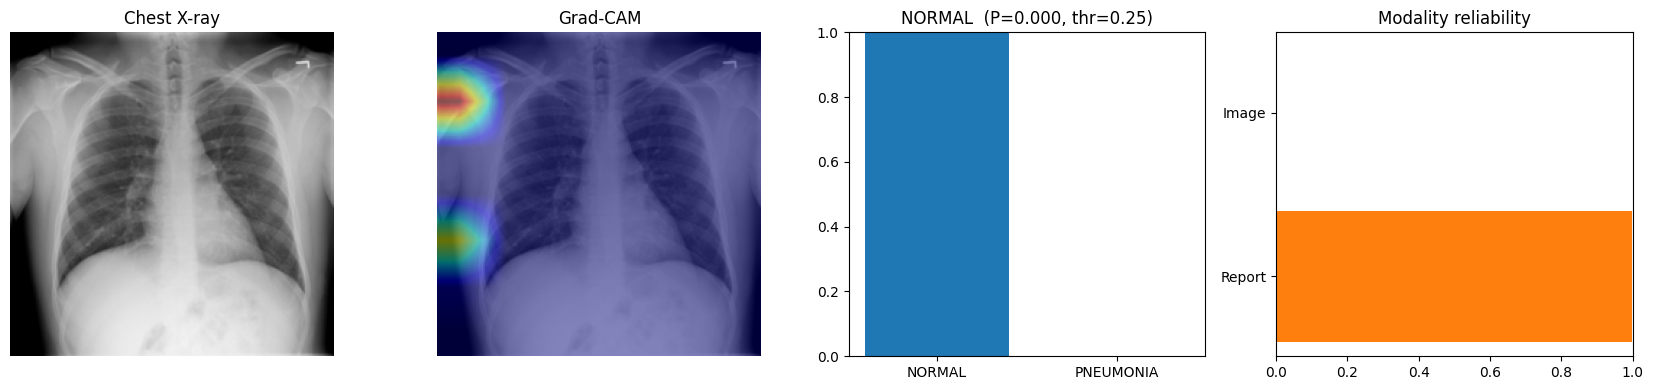

Prediction: NORMAL | P(PNEUMONIA)=0.0005  P(NORMAL)=0.9995 | threshold 0.25 | model: RA-GCMA (image + report) | reliability: image 0.003, report 0.997 | reference label: NORMAL
----------------------------------------------------------------------------------------------------


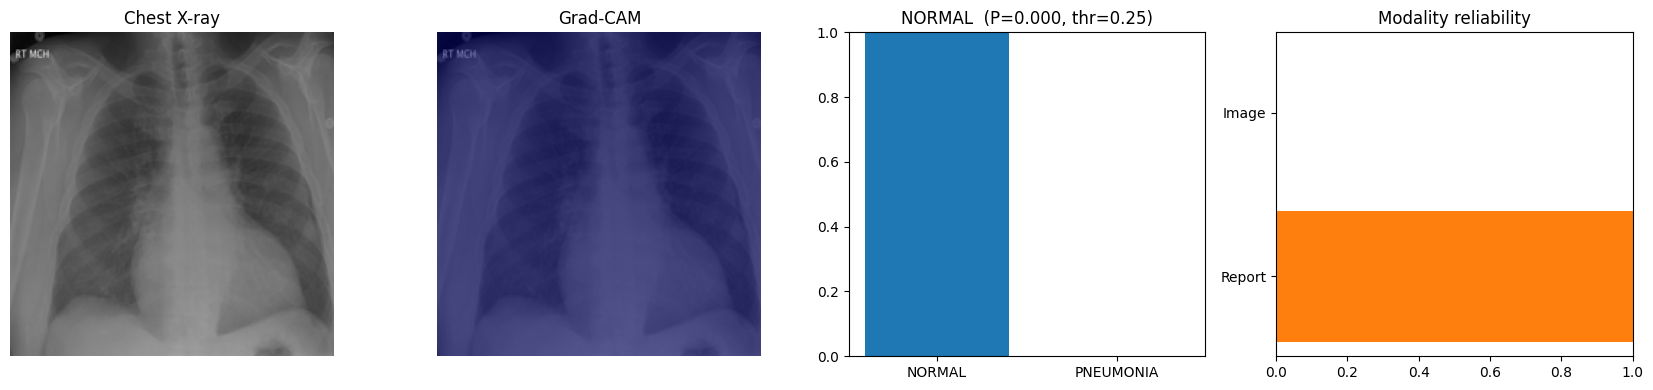

Prediction: NORMAL | P(PNEUMONIA)=0.0000  P(NORMAL)=1.0000 | threshold 0.25 | model: RA-GCMA (image + report) | reliability: image 0.000, report 1.000 | reference label: NORMAL
----------------------------------------------------------------------------------------------------


,case,truth,prediction,p_pneumonia,p_normal,w_image,w_report,correct
0,CXR2843,PNEUMONIA,NORMAL,0.0047,0.9953,0.179,0.821,False
1,CXR3878,PNEUMONIA,PNEUMONIA,0.8291,0.1709,0.537,0.463,True
2,CXR343,PNEUMONIA,NORMAL,0.0153,0.9847,0.115,0.885,False
3,CXR757,NORMAL,NORMAL,0.0001,0.9999,0.000,1.000,True
4,CXR1350,NORMAL,NORMAL,0.0005,0.9995,0.003,0.997,True
5,CXR3905,NORMAL,NORMAL,0.0000,1.0000,0.000,1.000,True


4/6 of these 6 cases correct. This is only a demo of the few cases above - the real held-out performance is Table 2 (all test cases).

Research demo only - not a medical device and not a substitute for professional diagnosis.


In [ ]:
# ============================================================
#  PNEUMONIA vs NORMAL IDENTIFICATION  (runs directly in Colab, no Gradio)
#  Run this AFTER the training cells (nets, res, df, te_idx, tok, tf, POS_I ... must exist).
# ============================================================
import matplotlib.cm as cm
from transformers import BertModel

# ---- inputs ---------------------------------------------------------------------------
# Leave both as None  -> classify real HELD-OUT TEST cases (X-ray + its own report).
# Or set IMAGE_PATH to a chest X-ray already in Colab (e.g. '/content/my_xray.png') and, optionally,
# REPORT_TEXT to its radiology report (without a report the image-only ResNet50 model is used).
IMAGE_PATH     = None
REPORT_TEXT    = None
N_PER_CLASS    = 3          # held-out test cases shown per class when IMAGE_PATH is None

# save the trained weights so they can be reused without retraining
torch.save({k: n.state_dict() for k, n in nets.items()}, '/content/outputs/ragcma_weights.pt')

# encoders for single samples (the batch encoders were freed during training)
_rn  = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
body = nn.Sequential(*list(_rn.children())[:-2]).to(dev).eval(); del _rn
bert = BertModel.from_pretrained(NAME, add_pooling_layer=False).to(dev).eval()

# decision threshold chosen on the VALIDATION set (best F1) - never on the test set
yv = df.label.values[va_idx]
def best_thr(mode):
    p, _ = predict(nets[mode], V[va_idx], Tt[va_idx], M[va_idx])
    ths = np.linspace(.05, .95, 91)
    return float(ths[np.argmax([f1_score(yv, (p >= t).astype(int), zero_division=0) for t in ths])])
THR = {'ragcma': best_thr('ragcma'), 'image': best_thr('image')}
print('validation-selected thresholds:', THR)

def identify(image, report=None, truth=None, show=True):
    """image: PIL image or file path. report: radiology report text or None. Returns a dict with the result."""
    img = (image if isinstance(image, Image.Image) else Image.open(image)).convert('RGB')
    x = tf(img).unsqueeze(0).to(dev)
    with torch.no_grad(), torch.autocast(dev, enabled=(dev == 'cuda')):
        v = body(x).flatten(2).transpose(1, 2).float()                     # 1 x 49 x 2048 visual tokens

    report = (report or '').strip(); use_text = len(report) >= 10
    if use_text:
        clean = POS_I.sub('', report) if MASK_LABEL_TERMS else report      # same masking as in training
        e = tok([clean], padding='max_length', truncation=True, max_length=CFG['max_len'], return_tensors='pt').to(dev)
        with torch.no_grad(), torch.autocast(dev, enabled=(dev == 'cuda')):
            t = bert(**e).last_hidden_state.float()
        m, mode = e['attention_mask'], 'ragcma'
    else:                                                                  # no report -> image-only model
        t = torch.zeros(1, CFG['max_len'], 768, device=dev)
        m, mode = torch.ones(1, CFG['max_len'], dtype=torch.long, device=dev), 'image'

    net = nets[mode].eval(); v = v.clone().requires_grad_(True); net.zero_grad()
    lg, gate = net(v, t, m)
    p1 = torch.softmax(lg, -1)[0, 1].item()
    lg[0, 1].backward()                                                    # Grad-CAM on the visual tokens
    cam = F.relu((v.detach() * v.grad.mean(1).unsqueeze(1)).sum(-1)).reshape(1, 1, 7, 7)
    cam = F.interpolate(cam, size=(224, 224), mode='bilinear')[0, 0].cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    thr = THR[mode]; label = 'PNEUMONIA' if p1 >= thr else 'NORMAL'
    g = None if gate is None else gate[0].detach().cpu().numpy()
    out = dict(prediction=label, p_pneumonia=round(p1, 4), p_normal=round(1 - p1, 4), threshold=round(thr, 2),
               model='RA-GCMA (image + report)' if use_text else 'ResNet50 image-only (no report given)',
               w_image=None if g is None else round(float(g[0]), 3), w_report=None if g is None else round(float(g[1]), 3), truth=truth)
    if show:
        small = img.resize((224, 224)); n = 4 if g is not None else 3
        fig, ax = plt.subplots(1, n, figsize=(4.2 * n, 4))
        ax[0].imshow(small); ax[0].set_title('Chest X-ray'); ax[0].axis('off')
        ax[1].imshow(small); ax[1].imshow(cam, cmap='jet', alpha=.45); ax[1].set_title('Grad-CAM'); ax[1].axis('off')
        ax[2].bar(['NORMAL', 'PNEUMONIA'], [1 - p1, p1], color=['#1f77b4', '#d62728']); ax[2].set_ylim(0, 1)
        ax[2].set_title(f'{label}  (P={p1:.3f}, thr={thr:.2f})')
        if g is not None:
            ax[3].barh(['Report', 'Image'], [g[1], g[0]], color=['#ff7f0e', '#1f77b4']); ax[3].set_xlim(0, 1)
            ax[3].set_title('Modality reliability')
        plt.tight_layout(); plt.show()
    print(f"Prediction: {label} | P(PNEUMONIA)={p1:.4f}  P(NORMAL)={1-p1:.4f} | threshold {thr:.2f} | model: {out['model']}"
          + ('' if g is None else f" | reliability: image {g[0]:.3f}, report {g[1]:.3f}")
          + ('' if truth is None else f" | reference label: {truth}"))
    return out

if IMAGE_PATH:                                                             # ---- your own image ----
    identify(IMAGE_PATH, REPORT_TEXT)
else:                                                                      # ---- held-out test cases ----
    pos = [int(i) for i in te_idx if df.label[i] == 1][:N_PER_CLASS]
    neg = [int(i) for i in te_idx if df.label[i] == 0][:N_PER_CLASS]
    rows = []
    for i in pos + neg:
        r = identify(df.img[i], df.text[i], truth='PNEUMONIA' if df.label[i] else 'NORMAL')
        rows.append({'case': df.uid[i], **r}); print('-' * 100)
    tbl = pd.DataFrame(rows); tbl['correct'] = tbl.prediction == tbl.truth
    display(tbl[['case', 'truth', 'prediction', 'p_pneumonia', 'p_normal', 'w_image', 'w_report', 'correct']])
    print(f"{int(tbl.correct.sum())}/{len(tbl)} of these {len(tbl)} cases correct. This is only a demo of the few cases above - "
          "the real held-out performance is Table 2 (all test cases).")
print('\nResearch demo only - not a medical device and not a substitute for professional diagnosis.')

## 11. Zip everything for download

In [ ]:
!cd /content && zip -qr outputs.zip outputs
from google.colab import files; files.download('/content/outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>